# 02 · Forecast backtest for all 150 SKUs
The Excel model (`excel/Inventory_Planning_Model.xlsx`, sheet **Forecast**) shows the four forecast methods with real
formulas for **one SKU at a time**. Power BI and SQL need the results for **every** SKU, so this notebook runs exactly the
same formulas in a loop. No machine learning, just the four textbook methods:

| Method | Forecast for every future week | Setting |
|---|---|---|
| **Naive** | the last actual week | none |
| **Moving average** | average of the last 8 weeks | window = 8 weeks |
| **Simple exponential smoothing (SES)** | the smoothed level: `level = α × actual + (1 − α) × previous level` | α chosen per SKU |
| **Holt-Winters (additive)** | level + trend × weeks ahead + the seasonal effect for that week last year | α, β, γ chosen per SKU |

**Backtest:** pretend it is the end of August 2011. Fit each method on weeks 1–91, forecast weeks 92–103
(Sep–Nov 2011) in one go, then compare with what really happened.

**Accuracy measures:**
- **WAPE** = Σ |forecast − actual| ÷ Σ actual. "On average the forecast is wrong by X% of demand." Works with zero weeks.
- **MAPE** = average of |forecast − actual| ÷ actual, over weeks with actual > 0 (it breaks when actual is 0).
- **Bias** = Σ (forecast − actual) ÷ Σ actual. Negative = under-forecasting (risk of stock-outs), positive = over-forecasting (excess stock).

**Choosing a method per class:** for each ABC–XYZ box, the method with the lowest **WAPE + |bias|**.
Using both stops us picking a method that is accurate on average but always too low.
Holt-Winters is only used for SKUs flagged seasonal in notebook 01.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", "{:,.3f}".format)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
IMG = ROOT / "docs" / "images"

sku = pd.read_csv(DATA / "sku_list.csv", dtype={"stock_code": str})
weekly = pd.read_csv(DATA / "weekly_demand.csv", dtype={"stock_code": str}, parse_dates=["week_start"])
weeks = pd.read_csv(DATA / "weeks.csv", parse_dates=["week_start"])

N_WEEKS, TRAIN, HORIZON, SEASON = 103, 91, 12, 52
MA_WINDOW, HW_SMOOTH = 8, 9
mat = weekly.pivot(index="stock_code", columns="week_no", values="demand_units").loc[sku.stock_code]
print(mat.shape)

(150, 103)


## 1. The four methods
Each function takes the history of one SKU (a list of weekly demand) and returns the forecast for the next 12 weeks.
SES and Holt-Winters also return the **one-step-ahead fit error** on the history, which we use to choose α, β, γ:
for every combination on a small grid, run through the history and keep the one with the smallest squared error.

Holt-Winters start values (the Excel sheet does the same):
- **level** = average of the first 52 weeks, **trend** = 0
- **seasonal effect** of each week in year 1 = a 9-week centred average around that week − the level.
  The 9-week average smooths out week-to-week noise, so the seasonal pattern isn't just last year's random spikes.

In [2]:
def naive(x, h=HORIZON):
    return np.repeat(x[-1], h).astype(float)


def moving_average(x, n=MA_WINDOW, h=HORIZON):
    return np.repeat(np.mean(x[-n:]), h)


def ses(x, alpha, h=HORIZON):
    # level starts at the first week; the forecast for week t is the level after week t-1
    level, sse = x[0], 0.0
    for v in x[1:]:
        sse += (v - level) ** 2
        level = alpha * v + (1 - alpha) * level
    return np.repeat(level, h), sse


def seasonal_start(train_x, m=SEASON, w=HW_SMOOTH):
    # centred w-week average of the training weeks, used for the first-year seasonal effects
    smooth = pd.Series(train_x).rolling(w, center=True, min_periods=1).mean().to_numpy()
    level0 = np.mean(train_x[:m])
    return level0, smooth[:m] - level0


def holt_winters(x, alpha, beta, gamma, start, m=SEASON, h=HORIZON):
    level, season0 = start
    trend, season, sse = 0.0, list(season0), 0.0
    for i in range(m, len(x)):
        fit = level + trend + season[i - m]
        sse += (x[i] - fit) ** 2
        prev = level
        level = alpha * (x[i] - season[i - m]) + (1 - alpha) * (level + trend)
        trend = beta * (level - prev) + (1 - beta) * trend
        season.append(gamma * (x[i] - level) + (1 - gamma) * season[i - m])
    n = len(x)
    fc = [level + k * trend + season[n + k - 1 - m] for k in range(1, h + 1)]
    return np.maximum(fc, 0), sse          # demand can't be negative


SES_GRID = np.round(np.arange(0.05, 1.0, 0.05), 2)
HW_GRID = list(product([0.05, 0.1, 0.2, 0.3], [0.0, 0.05], [0.0, 0.1, 0.2]))

## 2. Run the backtest (fit on weeks 1–91, forecast 92–103) and the future forecast (from week 103, for 104–115)
The parameters are chosen on the training weeks only. For the future forecast the same parameters are run over all
103 weeks, so the latest actuals are included.

In [3]:
METHODS = ["Naive", "Moving average", "SES", "Holt-Winters"]
params, fc_rows = [], []

for code, row in mat.iterrows():
    x = row.to_numpy(dtype=float)
    train_x = x[:TRAIN]
    alpha = min(SES_GRID, key=lambda a: ses(train_x, a)[1])
    start = seasonal_start(train_x)
    hw_p = min(HW_GRID, key=lambda p: holt_winters(train_x, *p, start)[1])
    params.append({"stock_code": code, "ses_alpha": alpha, "hw_alpha": hw_p[0], "hw_beta": hw_p[1], "hw_gamma": hw_p[2]})

    for run, hist, first_week in [("Backtest", train_x, TRAIN + 1), ("Future", x, N_WEEKS + 1)]:
        forecasts = {"Naive": naive(hist), "Moving average": moving_average(hist), "SES": ses(hist, alpha)[0],
                     "Holt-Winters": holt_winters(hist, *hw_p, start)[0]}
        for method, f in forecasts.items():
            for k in range(HORIZON):
                fc_rows.append({"stock_code": code, "run": run, "method": method, "week_no": first_week + k,
                                "horizon": k + 1, "forecast_units": round(float(f[k]), 4)})

params = pd.DataFrame(params)
fc = pd.DataFrame(fc_rows)
print(f"{len(fc):,} forecast rows")
params.describe()

14,400 forecast rows


,ses_alpha,hw_alpha,hw_beta,hw_gamma
count,150.000,150.000,150.000,150.000
mean,0.249,0.158,0.005,0.000
std,0.201,0.111,0.015,0.000
min,0.050,0.050,0.000,0.000
25%,0.100,0.050,0.000,0.000
50%,0.200,0.100,0.000,0.000
75%,0.350,0.300,0.000,0.000
max,0.950,0.300,0.050,0.000


Holt-Winters always gets **γ = 0** (keep last year's seasonal pattern, don't update it). With one and a bit years of
history there is no second Christmas in the training data to learn from, so that is expected.

In [4]:
params[["hw_alpha", "hw_beta", "hw_gamma"]].value_counts().head(8)

hw_alpha  hw_beta  hw_gamma
0.050     0.000    0.000       54
0.300     0.000    0.000       50
0.200     0.000    0.000       20
0.050     0.050    0.000       11
0.100     0.000    0.000       11
          0.050    0.000        4
Name: count, dtype: int64

## 3. Accuracy per SKU and method (test weeks 92–103)

In [5]:
actual = weekly[["stock_code", "week_no", "demand_units"]]
bt = fc[fc.run == "Backtest"].merge(actual, on=["stock_code", "week_no"])
bt["error"] = bt["forecast_units"] - bt["demand_units"]
bt["abs_error"] = bt["error"].abs()
bt["ape"] = np.where(bt["demand_units"] > 0, bt["abs_error"] / bt["demand_units"].where(bt["demand_units"] > 0), np.nan)

acc = (bt.groupby(["stock_code", "method"])
         .agg(actual_units=("demand_units", "sum"), forecast_units=("forecast_units", "sum"),
              sum_error=("error", "sum"), sum_abs_error=("abs_error", "sum"),
              sum_sq_error=("error", lambda e: (e ** 2).sum()),
              mape=("ape", "mean"), weeks_nonzero=("ape", "count"))
         .reset_index())
acc["wape"] = acc["sum_abs_error"] / acc["actual_units"]
acc["bias"] = acc["sum_error"] / acc["actual_units"]
acc = acc.merge(sku[["stock_code", "abc", "xyz", "abc_xyz", "is_seasonal"]], on="stock_code")

overall = acc.groupby("method").apply(lambda g: pd.Series({
    "WAPE": g.sum_abs_error.sum() / g.actual_units.sum(),
    "Bias": g.sum_error.sum() / g.actual_units.sum(),
    "MAPE (median SKU)": g.mape.median()}), include_groups=False).loc[METHODS]
overall

,WAPE,Bias,MAPE (median SKU)
method,,,
Naive,0.704,-0.343,0.640
Moving average,0.600,-0.226,0.696
SES,0.589,-0.222,0.718
Holt-Winters,0.624,0.085,0.838


All three flat methods (naive, moving average, SES) **under-forecast** the test weeks by 20–35%: September to November is
the Christmas run-up, and a flat forecast made in August can't see it coming. Holt-Winters is the only method that
expects the rise, so its bias is much smaller. Its WAPE isn't better, though, because copying last year's weekly pattern
also copies some of last year's noise. That's why the choice uses **WAPE and bias together**.

In [6]:
# the same comparison for seasonal vs non-seasonal SKUs
acc.groupby(["is_seasonal", "method"]).apply(lambda g: pd.Series({
    "WAPE": g.sum_abs_error.sum() / g.actual_units.sum(),
    "Bias": g.sum_error.sum() / g.actual_units.sum()}), include_groups=False).unstack("method")

WAPE                                    Bias  \
method      Holt-Winters Moving average Naive   SES Holt-Winters   
is_seasonal                                                        
False              0.626          0.619 0.615 0.608       -0.068   
True               0.624          0.592 0.739 0.582        0.144   

                                          
method      Moving average  Naive    SES  
is_seasonal                               
False                0.068 -0.335  0.073  
True                -0.339 -0.346 -0.335

## 4. Best method per ABC–XYZ class
For each of the 9 boxes: WAPE and bias over all SKUs in the box, score = WAPE + |bias|, lowest score wins.
Every SKU then uses its box's method, rather than its own best method. A single SKU's "best" over only 12 weeks is
often luck, so a class-level choice is more stable.

If the winner is Holt-Winters but a SKU isn't seasonal, that SKU gets the box's best non-seasonal method.

In [7]:
cls = (acc.groupby(["abc_xyz", "method"])
          .agg(skus=("stock_code", "nunique"), actual_units=("actual_units", "sum"),
               sum_abs_error=("sum_abs_error", "sum"), sum_error=("sum_error", "sum"))
          .reset_index())
cls["wape"] = cls["sum_abs_error"] / cls["actual_units"]
cls["bias"] = cls["sum_error"] / cls["actual_units"]
cls["score"] = cls["wape"] + cls["bias"].abs()
cls["rank"] = cls.groupby("abc_xyz")["score"].rank(method="first").astype(int)
cls["is_best"] = cls["rank"] == 1
best_flat = cls[cls.method != "Holt-Winters"].sort_values("score").drop_duplicates("abc_xyz").set_index("abc_xyz")["method"]
best_any = cls[cls.is_best].set_index("abc_xyz")["method"]

cls.pivot(index="abc_xyz", columns="method", values="score")[METHODS].assign(best=best_any)

method,Naive,Moving average,SES,Holt-Winters,best
abc_xyz,,,,,
AX,0.765,0.471,0.474,0.614,Moving average
AY,1.139,0.860,0.897,0.711,Holt-Winters
AZ,1.273,1.423,1.302,0.914,Holt-Winters
BX,0.586,0.607,0.572,0.616,SES
BY,1.254,0.881,0.748,0.662,Holt-Winters
BZ,1.735,1.446,1.436,1.077,Holt-Winters
CX,0.845,0.678,0.635,1.060,SES
CY,0.830,0.792,0.785,1.394,SES
CZ,1.562,1.133,1.124,1.694,SES


In [8]:
sku_choice = sku[["stock_code", "abc_xyz", "is_seasonal"]].copy()
sku_choice["class_best"] = sku_choice["abc_xyz"].map(best_any)
sku_choice["chosen_method"] = np.where((sku_choice.class_best == "Holt-Winters") & ~sku_choice.is_seasonal,
                                       sku_choice["abc_xyz"].map(best_flat), sku_choice.class_best)
params = params.merge(sku_choice[["stock_code", "chosen_method"]], on="stock_code")
fc = fc.merge(params[["stock_code", "chosen_method"]], on="stock_code")
fc["is_chosen"] = fc["method"] == fc["chosen_method"]
fc = fc.drop(columns="chosen_method")
params["chosen_method"].value_counts()

chosen_method
Holt-Winters      54
Moving average    44
SES               40
Naive             12
Name: count, dtype: int64

In [9]:
# how good is the chosen method overall, compared with using one method for everything?
chosen_acc = acc.merge(params[["stock_code", "chosen_method"]], on="stock_code").query("method == chosen_method")
summary = overall[["WAPE", "Bias"]].copy()
summary.loc["Chosen per class"] = [chosen_acc.sum_abs_error.sum() / chosen_acc.actual_units.sum(),
                                   chosen_acc.sum_error.sum() / chosen_acc.actual_units.sum()]
summary["WAPE + |bias|"] = summary["WAPE"] + summary["Bias"].abs()
summary

,WAPE,Bias,WAPE + |bias|
method,,,
Naive,0.704,-0.343,1.047
Moving average,0.600,-0.226,0.825
SES,0.589,-0.222,0.811
Holt-Winters,0.624,0.085,0.710
Chosen per class,0.609,0.037,0.646


## 5. Charts for the README

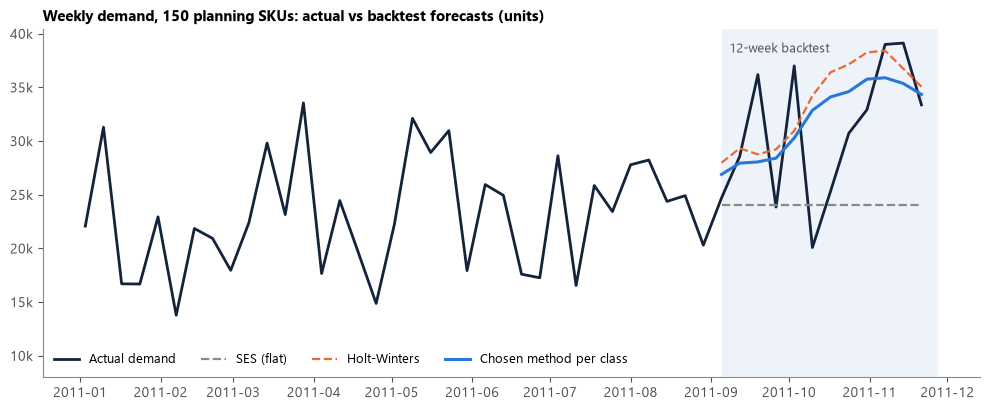

In [10]:
plt.rcParams.update({"font.family": "Segoe UI", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8A8A85", "axes.labelcolor": "#3D3D3A", "xtick.color": "#52514E",
                     "ytick.color": "#52514E", "axes.titleweight": "bold", "axes.titlesize": 11})
INK, BLUE, ORANGE, GREY = "#13233A", "#2A78D6", "#EB6834", "#8A8A85"

# total demand of the 150 SKUs: actual vs the backtest forecasts
tot_actual = weekly.groupby("week_start")["demand_units"].sum()
tot_fc = (fc[fc.run == "Backtest"].merge(weeks[["week_no", "week_start"]], on="week_no")
            .groupby(["method", "week_start"])["forecast_units"].sum().unstack("method"))
chosen_tot = (fc[(fc.run == "Backtest") & fc.is_chosen].merge(weeks[["week_no", "week_start"]], on="week_no")
                .groupby("week_start")["forecast_units"].sum())

fig, ax = plt.subplots(figsize=(10, 4.2))
recent = tot_actual[tot_actual.index >= "2011-01-03"]
ax.plot(recent.index, recent.values, color=INK, lw=2, label="Actual demand")
ax.plot(tot_fc.index, tot_fc["SES"], color=GREY, lw=1.6, ls="--", label="SES (flat)")
ax.plot(tot_fc.index, tot_fc["Holt-Winters"], color=ORANGE, lw=1.6, ls="--", label="Holt-Winters")
ax.plot(chosen_tot.index, chosen_tot.values, color=BLUE, lw=2.2, label="Chosen method per class")
ax.axvspan(pd.Timestamp("2011-09-05"), pd.Timestamp("2011-11-27"), color="#EEF3FA", zorder=0)
ax.text(pd.Timestamp("2011-09-08"), ax.get_ylim()[1] * 0.97, "12-week backtest", va="top", color="#52514E", fontsize=9)
ax.set_title("Weekly demand, 150 planning SKUs: actual vs backtest forecasts (units)", loc="left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.set_ylim(8000, None)
ax.legend(frameon=False, ncol=4, loc="lower left", fontsize=9)
fig.tight_layout()
fig.savefig(IMG / "backtest_total_demand.png", dpi=150)
plt.show()

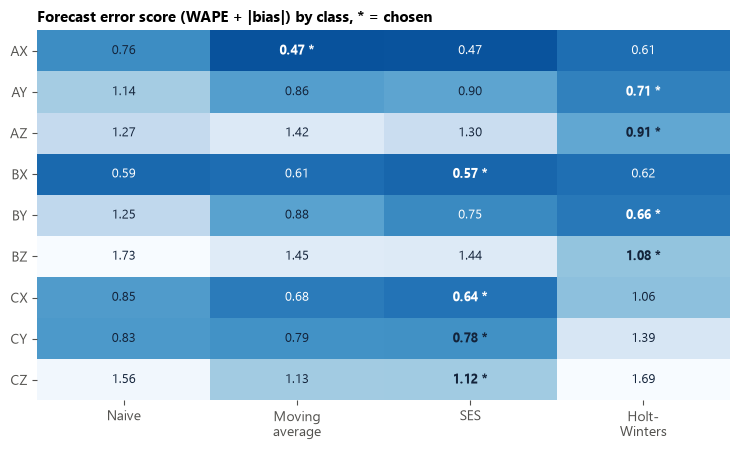

In [11]:
score = cls.pivot(index="abc_xyz", columns="method", values="score")[METHODS]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(score.to_numpy(), cmap="Blues_r", aspect="auto", vmin=0.3, vmax=1.6)
ax.set_xticks(range(4), ["Naive", "Moving\naverage", "SES", "Holt-\nWinters"])
ax.set_yticks(range(len(score)), score.index)
for i, c in enumerate(score.index):
    for j, m in enumerate(METHODS):
        v = score.loc[c, m]
        best = best_any[c] == m
        ax.text(j, i, f"{v:.2f}" + (" *" if best else ""), ha="center", va="center", fontsize=9,
                color="white" if v < 0.75 else INK, fontweight="bold" if best else "normal")
ax.set_title("Forecast error score (WAPE + |bias|) by class, * = chosen", loc="left")
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(IMG / "method_score_by_class.png", dpi=150)
plt.show()

## 6. Save

In [12]:
acc_out = acc[["stock_code", "method", "abc_xyz", "actual_units", "forecast_units", "sum_error", "sum_abs_error",
               "sum_sq_error", "wape", "bias", "mape", "weeks_nonzero"]].round(6)
cls_out = cls[["abc_xyz", "method", "skus", "actual_units", "sum_abs_error", "sum_error", "wape", "bias", "score",
               "rank", "is_best"]].round(6)

params.to_csv(DATA / "model_params.csv", index=False)
fc.to_csv(DATA / "forecasts.csv", index=False)
acc_out.to_csv(DATA / "forecast_accuracy.csv", index=False)
cls_out.to_csv(DATA / "method_by_class.csv", index=False)
for n, t in [("model_params", params), ("forecasts", fc), ("forecast_accuracy", acc_out), ("method_by_class", cls_out)]:
    print(f"{n:<18} {len(t):>6,} rows")

model_params          150 rows
forecasts          14,400 rows
forecast_accuracy     600 rows
method_by_class        36 rows
